# Tuần 03 — Thực hành kNN: 4 bài

Demo `01_Demo-kNN.ipynb` dừng ở việc **vote nhãn cho một mẫu test**.

Notebook này có **4 bài**. Mỗi bài là một bộ dữ liệu trên Kaggle. Cả 4 bài đều làm.

Viết hàm kNN một lần ở phần chung (NumPy, không dùng `KNeighborsClassifier`), rồi áp vào từng bài. Điền các ô có `???`. Giữ `np.random.seed(3000)`.

Tải đủ 4 file, đặt vào thư mục `data/`:

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Iris Species | https://www.kaggle.com/datasets/uciml/iris | `data/Iris.csv` |
| 2 | Palmer Penguins | https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data | `data/penguins_size.csv` |
| 3 | Heart Failure Prediction | https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction | `data/heart.csv` |
| 4 | Mushroom Classification | https://www.kaggle.com/datasets/uciml/mushroom-classification | `data/mushrooms.csv` |


In [5]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder

np.set_printoptions(precision=3, suppress=True)


## Phần chung — hàm kNN

Các bài bên dưới gọi lại 4 hàm này.

**Chuẩn hóa min–max**, min/max tính trên từng cột của `x_train`, rồi áp cùng hai mốc đó cho `x_test`. Cột nào `max == min` thì giữ nguyên.

$$
x' = \frac{x - x_{min}}{x_{max} - x_{min}}
$$

**Khoảng cách Euclid** từ một mẫu test tới mọi dòng train:

$$
d_i = \sqrt{\sum_j (test_j - train_{i,j})^2}
$$

**Một mẫu:** lấy `K` chỉ số gần nhất (`np.argsort`), vote nhãn xuất hiện nhiều nhất. Hòa thì `np.argmax` trên `counts` chọn nhãn có mã nhỏ hơn.

**Cả tập test:** gọi dự đoán từng mẫu, trả về mảng nhãn cùng độ dài `x_test`.


In [6]:
import math
def chuan_hoa_minmax(x_train, x_test):
    so_cot = len(x_train[0])
    min_cols = []
    max_cols = []

    for j in range(so_cot):          
        cot = []                    
        for dong in x_train:         
            cot.append(dong[j])    
        min_cols.append(min(cot))    
        max_cols.append(max(cot))
    def chuan_hoa(bang):
        ket_qua = []
        for dong in bang:
            dong_moi = []
            for j in range(so_cot):
                if max_cols[j] == min_cols[j]:
                    dong_moi.append(dong[j]) 
                else:
                    dong_moi.append((dong[j] - min_cols[j]) / (max_cols[j] - min_cols[j]))
            ket_qua.append(dong_moi)
        return ket_qua
    x_train_scaled = chuan_hoa(x_train)
    x_test_scaled = chuan_hoa(x_test)
    return x_train_scaled, x_test_scaled


def tinh_khoang_cach(test_s, x_train):
    khoang_cach = []
    for i in x_train:
        tong = 0
        for j in range(len(test_s)):
            hieu = test_s[j] - i[j]
            tong += hieu ** 2
        khoang_cach.append(math.sqrt(tong))
    return khoang_cach


def du_doan_1_mau(test_s, x_train, y_train, K):
    khoang_cach = tinh_khoang_cach(test_s, x_train)
    cap = []
    for i in range(len(khoang_cach)):
        cap.append((khoang_cach[i], y_train[i]))
    cap.sort()
    dem = {}
    for i in range(K):
        nhan = cap[i][1]
        if nhan in dem:
            dem[nhan] += 1
        else:
            dem[nhan] = 1
    nhan_tot_nhat = None
    so_lan_max = 0
    for nhan in dem:
        if dem[nhan] > so_lan_max:
            so_lan_max = dem[nhan]
            nhan_tot_nhat = nhan

    return nhan_tot_nhat
    


def du_doan_tap(x_test, x_train, y_train, K):
    ket_qua = []

    for mau in x_test:                                    
        nhan = du_doan_1_mau(mau, x_train, y_train, K)    
        ket_qua.append(nhan)                             

    return ket_qua


In [7]:
def chia_train_test(X, Y, ty_le=0.8, seed=3000):
    np.random.seed(seed)
    rand_indices = np.arange(len(Y))
    np.random.shuffle(rand_indices)
    n_train = int(ty_le * len(Y))
    train_idx = rand_indices[:n_train]
    test_idx = rand_indices[n_train:]
    return X[train_idx], Y[train_idx], X[test_idx], Y[test_idx]


def accuracy(y_pred, y_test):
    return np.mean(y_pred == y_test)


def ve_accuracy_theo_K(x_train, y_train, x_test, y_test, ds_K=None):
    if ds_K is None:
        ds_K = [1, 3, 5, 7, 9, 11, 13, 15]
    ds_acc = [accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test) for K in ds_K]
    print(list(zip(ds_K, np.round(ds_acc, 3))))
    plt.figure(figsize=(6, 4))
    plt.plot(ds_K, ds_acc, marker='o')
    plt.xlabel('K')
    plt.ylabel('accuracy')
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.show()
    return ds_K, ds_acc


---

# Bài 1 — Iris

Nguồn: https://www.kaggle.com/datasets/uciml/iris

File `data/Iris.csv`. 150 bông, 3 loài.

Cột: `Id`, `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, `Species`.

- Bỏ cột `Id`. Đó là số thứ tự, không phải số đo của hoa.
- Bốn cột đo là số (cm). Nhãn `Species` là chữ: dùng `LabelEncoder`.
- Chuẩn hóa min–max, rồi so sánh accuracy khi **có** và **không** chuẩn hóa (`K=5`).
- In kiểm tra mẫu test đầu tiên (khoảng cách K láng giềng, nhãn của họ, nhãn đoán, nhãn thật), rồi vẽ accuracy theo K.


In [8]:
df = pd.read_csv('data/Iris.csv')
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [9]:
from sklearn.preprocessing import LabelEncoder
raw_iris = np.genfromtxt('data/Iris.csv', delimiter=',', dtype=str, skip_header=1)
print(raw_iris.shape)
print(raw_iris[0])

# TODO: X_iris float (bỏ Id), Y_iris int
X_iris = raw_iris[:, 1:5].astype(float)
Y_iris = LabelEncoder().fit_transform(raw_iris[:, 5])

print(X_iris.shape, Y_iris.shape)
print(np.unique(Y_iris, return_counts=True))


(150, 6)
['1' '5.1' '3.5' '1.4' '0.2' 'Iris-setosa']
(150, 4) (150,)
(array([0, 1, 2]), array([50, 50, 50]))


accuracy K=5, đã chuẩn hóa: 0.9666666666666667
accuracy K=5, chưa chuẩn hóa: 0.9666666666666667
[(1, np.float64(0.967)), (3, np.float64(0.967)), (5, np.float64(0.967)), (7, np.float64(0.967)), (9, np.float64(0.967)), (11, np.float64(0.967)), (13, np.float64(0.967)), (15, np.float64(0.967))]


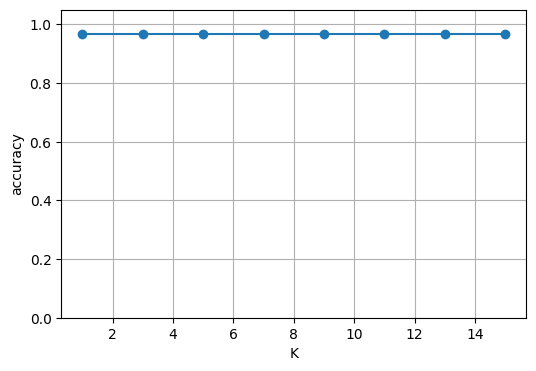

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667)])

In [10]:
x_train, y_train, x_test, y_test = chia_train_test(X_iris, Y_iris)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

K = 5
mau = x_test_s[0]                                  
khoang_cach = tinh_khoang_cach(mau, x_train_s)    
cap = []
for i in range(len(khoang_cach)):
    cap.append((khoang_cach[i], y_train[i]))
cap.sort()
k_khoang_cach = []
k_nhan = []
for i in range(K):
    k_khoang_cach.append(round(cap[i][0], 4))
    k_nhan.append(cap[i][1])

nhan_du_doan = du_doan_1_mau(mau, x_train_s, y_train, K)


print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, K), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 1**

1. `X` có bao nhiêu dòng, bao nhiêu cột? Có bao nhiêu lớp?
2. Accuracy tại `K=5` khi có chuẩn hóa và khi không chuẩn hóa chênh nhau thế nào? Vì sao với Iris mức chênh thường nhỏ?
3. Vì sao không đưa cột `Id` vào feature?


In [11]:
df.shape

(150, 6)

In [ ]:
# Bài 1
# 1. 150 dòng
# 2. khi chuẩn hóa và chưa chuẩn hóa không có chênh lệch. Nguyên nhân là bốn đặc trưng của Iris đều đo bằng cm và có cùng cỡ giá trị (khoảng từ 0,1 đến 7,9), nên không cột nào lấn át khoảng cách Euclid
# 3. Id chỉ là số thứ tự, không phải số đo của hoa. Nó không mang thông tin gì về loài hoa.Nó làm sai khoảng cách và gây nhiễu hoặc rò rỉ thông tin giả

(150, 6)

---

# Bài 2 — Palmer Penguins

Nguồn: https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data

File `data/penguins_size.csv`. Đoán loài chim cánh cụt.

Cột: `species`, `island`, `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex`.

- Bỏ mọi dòng có ô trống hoặc `NA`.
- Nhãn là `species`.
- `island` và `sex` là chữ: `LabelEncoder` **từng cột**.
- Bốn cột đo là số: `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`.
- Bắt buộc chuẩn hóa. `body_mass_g` khoảng vài nghìn, chiều dài mỏ khoảng vài chục. Không chuẩn hóa thì khoảng cách gần như chỉ còn khối lượng.


In [12]:
df_penguin = pd.read_csv('data/penguins_size.csv')

In [13]:
raw_pen = np.genfromtxt('data/penguins_size.csv', delimiter=',', dtype=str, skip_header=1)
print('trước khi bỏ dòng thiếu:', raw_pen.shape)

# TODO: bỏ dòng có '' hoặc 'NA', rồi tạo X_pen (float) và Y_pen (int)
df_penguin = df_penguin.dropna()
raw_pen = df_penguin.to_numpy()

giu = []
for dong in raw_pen:
    hop_le = True
    for o in dong:
        if str(o).strip() == '' or str(o).strip() == 'NA':
            hop_le = False
    if hop_le:
        giu.append(dong)
raw_pen = np.array(giu)

for i in [1, 6]:
    raw_pen[:, i] = LabelEncoder().fit_transform(raw_pen[:, i])

X_pen = raw_pen[:, 2:6].astype(float)
cac_loai, Y_pen = np.unique(raw_pen[:, 0], return_inverse=True)


trước khi bỏ dòng thiếu: (344, 7)


accuracy K=5, đã chuẩn hóa: 0.9850746268656716
accuracy K=5, chưa chuẩn hóa: 0.7761194029850746
[(1, np.float64(0.985)), (3, np.float64(0.985)), (5, np.float64(0.985)), (7, np.float64(0.985)), (9, np.float64(0.985)), (11, np.float64(0.985)), (13, np.float64(0.985)), (15, np.float64(0.985))]


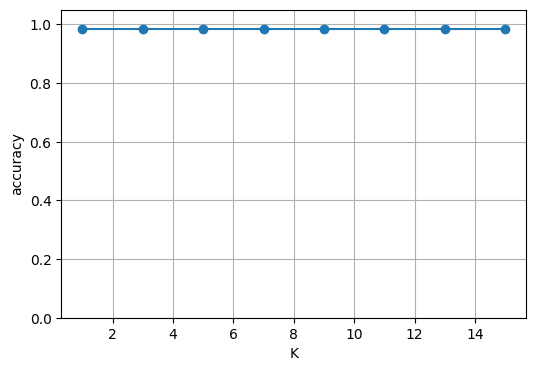

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716)])

In [14]:
x_train, y_train, x_test, y_test = chia_train_test(X_pen, Y_pen)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 2**

1. Bỏ bao nhiêu dòng vì thiếu dữ liệu?
2. Accuracy `K=5` khi chưa chuẩn hóa thấp hơn bản đã chuẩn hóa ra sao? Cột nào kéo khoảng cách Euclid?
3. `K` nào cho accuracy cao nhất trên đồ thị?


In [ ]:
# Bài 2
# 1. Bỏ 10 dòng bị khuyết dữ liệu (từ 344 dòng xuống còn 334 dòng).
# 2. Accuracy K=5 khi chưa chuẩn hóa giảm xuống còn khoảng 0.776 so với 0.985 khi đã chuẩn hóa. Cột body_mass_g với giá trị cực lớn 
# đã lấn át và kéo lệch hoàn toàn khoảng cách Euclid.
# 3. K = 1, 3, 5, 7, 9, 11, 13, 15 đều cho ra accuracy cao nhất là 0.985 trên đồ thị.


---

# Bài 3 — Heart Failure Prediction

Nguồn: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

File `data/heart.csv`. 918 dòng. Đoán có bệnh tim hay không. Cùng kiểu bài với demo tình trạng xe.

Cột theo đúng thứ tự trong file:

`Age`, `Sex`, `ChestPainType`, `RestingBP`, `Cholesterol`, `FastingBS`, `RestingECG`, `MaxHR`, `ExerciseAngina`, `Oldpeak`, `ST_Slope`, `HeartDisease`.

- Nhãn `HeartDisease` đã là `0` / `1`.
- Cột chữ, `LabelEncoder` từng cột: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`.
- Cột số: `Age`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `Oldpeak`.
- Ghép các cột đã mã hóa thành một ma trận `X` kiểu float, rồi chuẩn hóa min–max.
- Hai lớp, nên các `K` đem thử là số lẻ.


In [15]:
df = pd.read_csv('data/heart.csv')

In [16]:
raw_heart = np.genfromtxt('data/heart.csv', delimiter=',', dtype=str, skip_header=1)
print(raw_heart.shape)
print(raw_heart[0])

# TODO: X_heart float, Y_heart int
processed_heart = np.copy(raw_heart)
for col in [1, 2, 6, 8, 10]:
    processed_heart[:, col] = LabelEncoder().fit_transform(raw_heart[:, col])

X_heart = processed_heart[:, :11].astype(float)
Y_heart = raw_heart[:, 11].astype(int)

print(X_heart.shape, Y_heart.shape)
print(np.unique(Y_heart, return_counts=True))


(918, 12)
['40' 'M' 'ATA' '140' '289' '0' 'Normal' '172' 'N' '0' 'Up' '0']
(918, 11) (918,)
(array([0, 1]), array([410, 508]))


accuracy K=5: 0.875
[(1, np.float64(0.87)), (3, np.float64(0.886)), (5, np.float64(0.875)), (7, np.float64(0.87)), (9, np.float64(0.87)), (11, np.float64(0.864)), (13, np.float64(0.87)), (15, np.float64(0.853))]


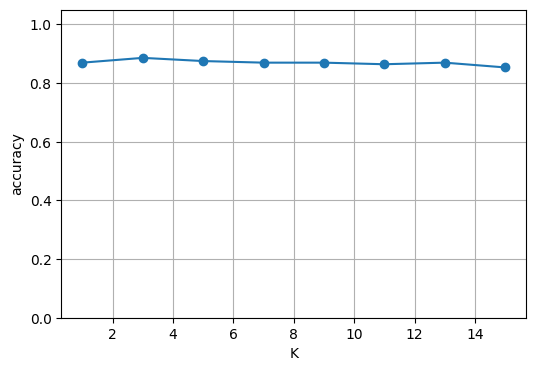

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(0.8695652173913043),
  np.float64(0.8858695652173914),
  np.float64(0.875),
  np.float64(0.8695652173913043),
  np.float64(0.8695652173913043),
  np.float64(0.8641304347826086),
  np.float64(0.8695652173913043),
  np.float64(0.8532608695652174)])

In [17]:
x_train, y_train, x_test, y_test = chia_train_test(X_heart, Y_heart)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 3**

1. Có bao nhiêu người trong tập test? Tỉ lệ lớp `0` và `1` trên toàn bộ dữ liệu là bao nhiêu?
2. Accuracy cao nhất và `K` tương ứng?
3. Vì sao với bài 2 lớp nên chọn `K` lẻ?


In [ ]:
# Bài 3
# 1. Có 184 người trong tập test (20% của 918). Tỷ lệ lớp 0 và 1 trên toàn bộ dữ liệu là 410 (lớp 0) và 508 (lớp 1).
# 2. Accuracy cao nhất là khoảng 0.886 đạt được ở K = 13.
# 3. Ở bài toán phân 2 lớp, nên chọn K là số lẻ để tránh tình trạng số phiếu hòa nhau (tie) giữa 2 lớp khi thực hiện quá trình vote nhãn.


---

# Bài 4 — Mushroom Classification

Nguồn: https://www.kaggle.com/datasets/uciml/mushroom-classification

File `data/mushrooms.csv`. Đoán nấm ăn được (`e`) hay độc (`p`).

Mọi cột đều là chữ, cùng kiểu demo xe. Cột 0 là nhãn `class`. Các cột còn lại là feature.

- Bỏ dòng nào còn giá trị `?`.
- `LabelEncoder` **từng cột** feature, rồi mã hóa riêng cột nhãn. Giống đoạn mã hóa trong demo xe.
- **Không** chuẩn hóa min–max. Mã `LabelEncoder` chỉ là tên nhóm được đánh số, không phải số đo cùng đơn vị.
- Tập này vài nghìn dòng. `tinh_khoang_cach` cần tính một lần cho cả `x_train` (vector), không viết vòng `for` từng dòng train.


In [20]:
raw_mush = np.genfromtxt('data/mushrooms.csv', delimiter=',', dtype=str, skip_header=1)
print('trước khi bỏ dòng có ?:', raw_mush.shape)

# TODO: bỏ dòng chứa '?', X_mush float, Y_mush int
giu_mush = []
for dong in raw_mush:
    if '?' not in dong:
        giu_mush.append(dong)
clean_mush = np.array(giu_mush)

processed_mush = np.copy(clean_mush)
for i in range(processed_mush.shape[1]):
    processed_mush[:, i] = LabelEncoder().fit_transform(clean_mush[:, i])

X_mush = processed_mush[:, 1:].astype(float)
Y_mush = processed_mush[:, 0].astype(int)

print(X_mush.shape, Y_mush.shape)
print(np.unique(Y_mush, return_counts=True))


trước khi bỏ dòng có ?: (8124, 23)
(5644, 22) (5644,)
(array([0, 1]), array([3488, 2156]))


accuracy K=5: 0.9991142604074402
[(1, np.float64(1.0)), (3, np.float64(1.0)), (5, np.float64(0.999)), (7, np.float64(0.999)), (9, np.float64(0.997)), (11, np.float64(0.998)), (13, np.float64(0.996)), (15, np.float64(0.996))]


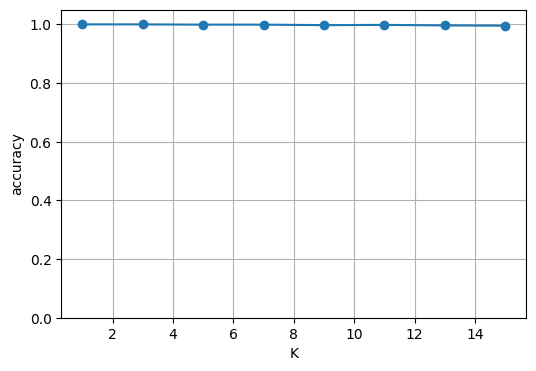

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(1.0),
  np.float64(1.0),
  np.float64(0.9991142604074402),
  np.float64(0.9991142604074402),
  np.float64(0.9973427812223207),
  np.float64(0.9982285208148804),
  np.float64(0.9964570416297609),
  np.float64(0.995571302037201)])

In [22]:
x_train, y_train, x_test, y_test = chia_train_test(X_mush, Y_mush)

# Không gọi chuan_hoa_minmax
print('accuracy K=5:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))
ve_accuracy_theo_K(x_train, y_train, x_test, y_test)


**Nộp kèm bài 4**

1. Còn bao nhiêu dòng sau khi bỏ `?`? Bao nhiêu feature?
2. Accuracy cao nhất và `K` tương ứng?
3. Bài này giống demo tình trạng xe ở bước nào, và khác bài 1–3 ở chỗ nào (chuẩn hóa)?


In [ ]:
# Bài 4
# 1. Còn lại 5644 dòng sau khi bỏ các dòng chứa '?'. Dữ liệu có tổng cộng 22 feature (bỏ đi 1 cột class làm nhãn).
# 2. Accuracy cao nhất là 1.0 (100%) đạt được ở K = 1, 3, 5.
# 3. Giống demo tình trạng xe ở bước dùng LabelEncoder mã hóa tất cả các cột chữ thành số. Khác ở chỗ bài này không cần bước chuẩn hóa min-max do các con số sau mã hóa chỉ mang ý nghĩa tên nhóm (category), không phải số lượng mang ý nghĩa độ lớn tuyến tính.
